# Small drops, big underestimate: drop-size-adaptive R(A) on KDAX and KTLX

**Problem.** On the 24 Oct 2021 atmospheric river (notebook 04, KDAX) every estimate got about half the
gauge-corrected rain, even over the open valley. Rain with many small drops gives more water for the same
reflectivity than continental rain, so relations tuned on big drops underestimate it.

**Fix** (`ZDRSlopeAlpha`): Wang et al. (2019, J. Hydrometeor., doi:10.1175/JHM-D-18-0071.1), as used in MRMS and
NEXRAD Build 19. Estimate alpha, the ratio of specific attenuation to KDP, from how fast ZDR rises with Z
(slope K): alpha = 0.04875 - 0.75 K, between 0.015 (continental) and 0.04 (tropical). R(A) scales almost linearly
with alpha. With an adaptive alpha, R(A) is used on rays with at least 10 deg of PHIDP span (the fixed-alpha
default is 40 deg, which this moderate rain rarely reaches).

**Test.** The same pipeline on two cases: KDAX (California, small drops) and KTLX (Oklahoma, continental, where
notebook 01-03 were already close). A fix that only helped KDAX by breaking KTLX would be no fix.
Pipeline: VPR correction, hybrid scan with the NEXRAD blockage correction (KDAX; KTLX terrain is flat),
synthetic rain rate, motion-following hourly totals. Reference: MRMS MultiSensor QPE Pass 2.

In [1]:
# Colab: uncomment to install
!pip install -q cfgrib eccodes pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-core" "git+https://github.com/manmeet3591/radarwow-kdp" "git+https://github.com/manmeet3591/radarwow-attenuation" "git+https://github.com/manmeet3591/radarwow-estimation" "git+https://github.com/manmeet3591/radarwow-classification" "git+https://github.com/manmeet3591/radarwow-verify"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import load_band, nexrad_aws_files, open_volume
from radarwow.estimation import (ADAPTIVE_MIN_DPHI, Bech2003BeamBlockage, SyntheticRainRate, ZDRSlopeAlpha, ZhangQi2010VPR,
                                 ZRRelation, advection_accumulate, below_melting_layer, copernicus_dem,
                                 fulton1998_correction_db, hybrid_scan, polar_to_cartesian, to_fixed_azimuths, unique_tilts)
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import fetch_mrms, hrrr_freezing_level, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
CASES = {"KDAX": dict(day="2021-10-24", hours=[12, 13, 14, 15], n_tilts=3, blockage=True),
         "KTLX": dict(day="2022-05-05", hours=[7, 8, 9, 10], n_tilts=1, blockage=False)}
METHODS = ["Z-R Marshall-Palmer", "synthetic, fixed alpha (before)", "synthetic, adaptive alpha"]
S = load_band("S")

## 1. Run both cases

In [3]:
def run_case(site, day, hours, n_tilts, blockage):
    files = nexrad_aws_files(site, f"{day} {hours[0] - 1:02d}:45", f"{day} {hours[-1] + 1:02d}:05", cache_dir=f"{CACHE}/nexrad")
    dt0 = open_volume(files[0][1], band="S")
    lat0, lon0, alt = (float(dt0[k].values) for k in ("latitude", "longitude", "altitude"))
    bb = Bech2003BeamBlockage(dem=copernicus_dem(lat0, lon0, 160, f"{CACHE}/dem"), site=(lat0, lon0, alt), beamwidth_deg=0.95) if blockage else None
    tracker, alpha_est, fz_cache = MeltingLayerTracker(), ZDRSlopeAlpha(), {}
    scans, log = {k: [] for k in METHODS}, []
    for t, f in files:
        try:
            dt = open_volume(f, band="S")
        except Exception:  # noqa: BLE001 - damaged archive file
            continue
        hr = pd.Timestamp(t).round("h")
        if hr not in fz_cache:
            fz_cache[hr] = (hrrr_freezing_level(hr, lat0, lon0, f"{CACHE}/hrrr", 150) - alt) / 1e3
        ml, _ = melting_layer_from_volume(dt)
        use, _ = tracker.update(t, ml, prior_top_km=fz_cache[hr])
        mlb = use.bottom_km if use else fz_cache[hr] - 0.5
        vdt = ZhangQi2010VPR(freezing_level_km=fz_cache[hr])(dt)
        per = {k: [] for k in METHODS} | {"cbb": []}
        for i, (el, name) in enumerate(unique_tilts(vdt)[:n_tilts]):
            ds = vdt[name].to_dataset().isel(range=slice(0, 600))
            if bb is not None:
                ds = bb(ds, band="S")
                corr = fulton1998_correction_db(ds["CBB"].values)
                cbb = ds["CBB"].values
            else:
                corr, cbb = np.zeros(ds["DBZH"].shape), np.zeros(ds["DBZH"].shape)
            below = below_melting_layer(ds, ml_bottom_km=mlb)
            if i == 0:
                alpha, k = alpha_est.update(t, ds, mask=below & (cbb < 0.1))
                log.append(dict(site=site, time=pd.Timestamp(t), K=k, alpha=alpha))
            dsc = ds.assign(DBZH=ds["DBZH_VPR"] + np.nan_to_num(corr))
            kd = Vulpiani2012KDP()(dsc, band="S")
            cfg_a = S.override(zphi_alpha=alpha, ra_min_dphi=ADAPTIVE_MIN_DPHI)
            rates = {"Z-R Marshall-Palmer": ZRRelation(preset="marshall_palmer", z_max_dbz=53)(dsc, band="S")["RATE_Z"],
                     "synthetic, fixed alpha (before)": SyntheticRainRate(temperature_c=15)(Testud2000ZPHI()(kd, band=S), band=S)["RATE"],
                     "synthetic, adaptive alpha": SyntheticRainRate(temperature_c=15)(Testud2000ZPHI()(kd, band=cfg_a), band=cfg_a)["RATE"]}
            ok = below & np.isfinite(corr)
            for m, r in rates.items():
                v = r.copy(data=np.where(ok, np.nan_to_num(r.values), np.nan))
                per[m].append(polar_to_cartesian(to_fixed_azimuths(v), el, max_km=150, res_km=1.0).values)
            per["cbb"].append(polar_to_cartesian(to_fixed_azimuths(ds["DBZH"].copy(data=cbb)), el, max_km=150, res_km=1.0).values)
        grid = polar_to_cartesian(to_fixed_azimuths(r), el, max_km=150, res_km=1.0)
        for m in METHODS:
            field, _ = hybrid_scan(list(zip(per[m], per["cbb"])))
            scans[m].append((t, grid.copy(data=field.astype("float32"))))
    xx, yy = np.meshgrid(grid["x"].values, grid["y"].values)
    geo = dict(lat=lat0 + yy / 111.2, lon=lon0 + xx / (111.2 * np.cos(np.deg2rad(lat0))), dist=np.hypot(xx, yy),
               open=per["cbb"][0] < 0.1)
    return scans, pd.DataFrame(log), geo


out = {site: run_case(site, **c) for site, c in CASES.items()}
alog = pd.concat([o[1] for o in out.values()])
display(Markdown("**Estimated ZDR-Z slope and alpha** (median over volumes)\n\n"
                 + alog.groupby("site")[["K", "alpha"]].median().round(3).to_markdown()))

**Estimated ZDR-Z slope and alpha** (median over volumes)

| site   |     K |   alpha |
|:-------|------:|--------:|
| KDAX   | 0.023 |   0.032 |
| KTLX   | 0.053 |   0.015 |

## 2. Hourly totals against MRMS

In [4]:
rows, maps = [], {}
for site, c in CASES.items():
    scans, _, g = out[site]
    for h in c["hours"]:
        a, b = pd.Timestamp(f"{c['day']} {h:02d}:00"), pd.Timestamp(f"{c['day']} {h + 1:02d}:00")
        ref = fetch_mrms("gauge_corrected", b, f"{CACHE}/mrms")
        ro = fetch_mrms("radar_only", b, f"{CACHE}/mrms")
        for area, m_ in [("all", g["dist"] <= 150), ("open terrain", (g["dist"] <= 150) & g["open"])]:
            if site == "KTLX" and area != "all":
                continue
            for m in METHODS:
                acc = advection_accumulate(scans[m], a, b)
                v = np.where((acc["VALID_MINUTES"].values >= 48) & m_, acc["ACCUM"].values, np.nan)
                if area == "all":
                    maps[(site, h, m)] = v
                o, r_, _ = to_mrms_grid(v, g["lat"], g["lon"], ref, g["dist"])
                rows.append(dict(site=site, area=area, hour=f"{h:02d}-{h + 1:02d}", method=m, **scores(o, r_)))
            ones = np.where(np.isfinite(v), 1.0, np.nan)
            _, rv, _ = to_mrms_grid(ones, g["lat"], g["lon"], ro, g["dist"])
            _, gv, _ = to_mrms_grid(ones, g["lat"], g["lon"], ref, g["dist"])
            rows.append(dict(site=site, area=area, hour=f"{h:02d}-{h + 1:02d}", method="MRMS radar-only", **scores(rv, gv)))
        maps[(site, h, "mrms")] = ref
res = pd.DataFrame(rows)
for (site, area), d in res.groupby(["site", "area"], sort=False):
    tab = d.pivot_table(index="method", columns="hour", values=["bias_ratio", "corr", "rmse"]).round(2)
    display(Markdown(f"**{site}, {area}** (bias = total / MRMS gauge-corrected total; RMSE in mm)\n\n"
                     + tab.loc[METHODS + ["MRMS radar-only"]].to_markdown()))

Pysteps configuration file found at: /Users/manmeet.singh/aircast/radar-wow/.venv/lib/python3.11/site-packages/pysteps/pystepsrc



**KDAX, all** (bias = total / MRMS gauge-corrected total; RMSE in mm)

| method                          |   ('bias_ratio', '12-13') |   ('bias_ratio', '13-14') |   ('bias_ratio', '14-15') |   ('bias_ratio', '15-16') |   ('corr', '12-13') |   ('corr', '13-14') |   ('corr', '14-15') |   ('corr', '15-16') |   ('rmse', '12-13') |   ('rmse', '13-14') |   ('rmse', '14-15') |   ('rmse', '15-16') |
|:--------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R Marshall-Palmer             |                      0.48 |                      0.45 |                      0.46 |                      0.49 |                0.72 |                0.76 |                0.81 |                0.82 |                4.2  |                4.12 |                3.67 |                3.43 |
| synthetic, fixed alpha (before) |                      0.49 |                      0.46 |                      0.47 |                      0.5  |                0.73 |                0.77 |                0.81 |                0.82 |                4.12 |                4.05 |                3.6  |                3.35 |
| synthetic, adaptive alpha       |                      0.81 |                      0.77 |                      0.76 |                      0.81 |                0.7  |                0.72 |                0.78 |                0.81 |                3.21 |                3    |                2.63 |                2.52 |
| MRMS radar-only                 |                      0.59 |                      0.56 |                      0.59 |                      0.6  |                0.84 |                0.83 |                0.84 |                0.85 |                3.33 |                3.32 |                2.93 |                2.77 |

**KDAX, open terrain** (bias = total / MRMS gauge-corrected total; RMSE in mm)

| method                          |   ('bias_ratio', '12-13') |   ('bias_ratio', '13-14') |   ('bias_ratio', '14-15') |   ('bias_ratio', '15-16') |   ('corr', '12-13') |   ('corr', '13-14') |   ('corr', '14-15') |   ('corr', '15-16') |   ('rmse', '12-13') |   ('rmse', '13-14') |   ('rmse', '14-15') |   ('rmse', '15-16') |
|:--------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R Marshall-Palmer             |                      0.51 |                      0.49 |                      0.5  |                      0.53 |                0.82 |                0.85 |                0.86 |                0.85 |                3.44 |                3.37 |                3.17 |                3.06 |
| synthetic, fixed alpha (before) |                      0.53 |                      0.5  |                      0.51 |                      0.55 |                0.82 |                0.85 |                0.86 |                0.86 |                3.36 |                3.29 |                3.1  |                2.97 |
| synthetic, adaptive alpha       |                      0.86 |                      0.81 |                      0.82 |                      0.88 |                0.81 |                0.84 |                0.86 |                0.85 |                2.58 |                2.19 |                2.06 |                2.23 |
| MRMS radar-only                 |                      0.65 |                      0.64 |                      0.68 |                      0.69 |                0.92 |                0.91 |                0.93 |                0.92 |                2.45 |                2.4  |                2.1  |                2.11 |

**KTLX, all** (bias = total / MRMS gauge-corrected total; RMSE in mm)

| method                          |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |   ('rmse', '07-08') |   ('rmse', '08-09') |   ('rmse', '09-10') |   ('rmse', '10-11') |
|:--------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R Marshall-Palmer             |                      1.04 |                      0.94 |                      1.07 |                      0.95 |                0.96 |                0.92 |                0.94 |                0.9  |                1.3  |                2.22 |                1.2  |                1.3  |
| synthetic, fixed alpha (before) |                      1.08 |                      1    |                      1.1  |                      0.97 |                0.97 |                0.95 |                0.95 |                0.88 |                1.13 |                1.66 |                1.05 |                1.39 |
| synthetic, adaptive alpha       |                      1.02 |                      1    |                      1.07 |                      0.99 |                0.97 |                0.95 |                0.95 |                0.89 |                1.02 |                1.66 |                1.01 |                1.34 |
| MRMS radar-only                 |                      1.12 |                      1.13 |                      1.32 |                      1.25 |                0.99 |                0.99 |                0.97 |                0.97 |                0.93 |                1.06 |                1.19 |                1.05 |

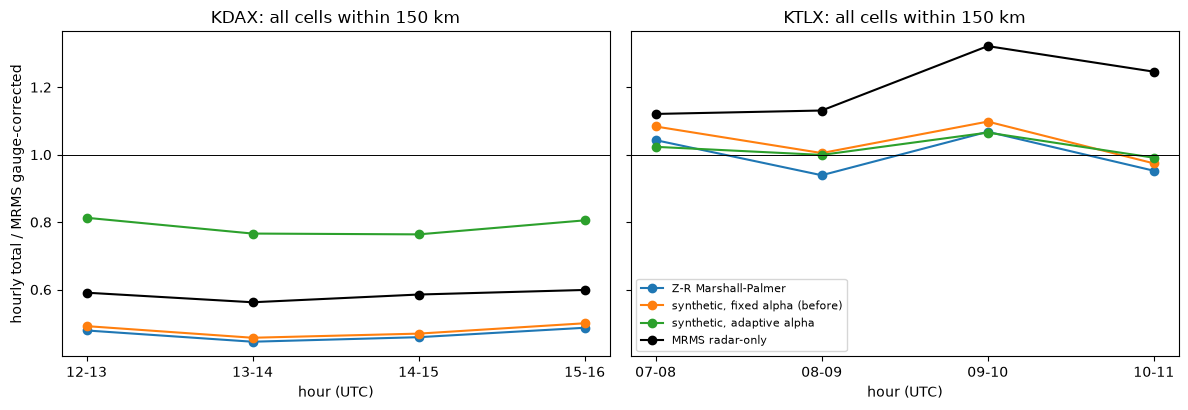

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, site in zip(axes, CASES):
    d = res[(res.site == site) & (res.area == "all")]
    for i, m in enumerate(METHODS + ["MRMS radar-only"]):
        g_ = d[d.method == m].sort_values("hour")
        ax.plot(g_.hour, g_.bias_ratio, "o-", color="k" if "MRMS" in m else f"C{i}", label=m)
    ax.axhline(1, color="k", lw=0.7)
    ax.set(title=f"{site}: all cells within 150 km", xlabel="hour (UTC)")
axes[0].set_ylabel("hourly total / MRMS gauge-corrected")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/13_adaptive_alpha_bias.png", dpi=110)
plt.show()

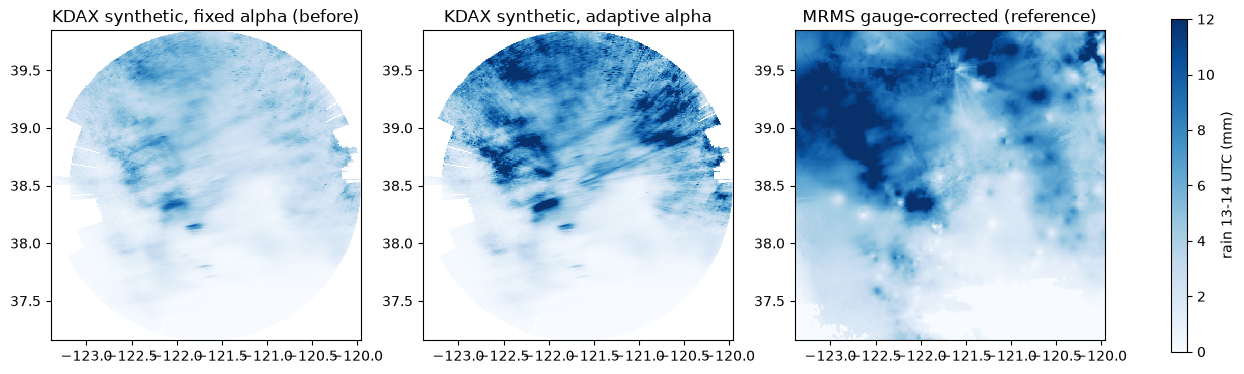

In [6]:
h = 13
g = out["KDAX"][2]
ref = maps[("KDAX", h, "mrms")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
kw = dict(cmap="Blues", vmin=0, vmax=12, shading="auto")
for ax, m in zip(axes[:2], ["synthetic, fixed alpha (before)", "synthetic, adaptive alpha"]):
    p = ax.pcolormesh(g["lon"], g["lat"], np.ma.masked_invalid(maps[("KDAX", h, m)]), **kw)
    ax.set_title(f"KDAX {m}")
box = ref.sel(latitude=slice(g["lat"].max(), g["lat"].min()), longitude=slice(g["lon"].min(), g["lon"].max()))
axes[2].pcolormesh(box.longitude, box.latitude, np.ma.masked_invalid(box.values), **kw)
axes[2].set_title("MRMS gauge-corrected (reference)")
for ax in axes:
    ax.set(xlim=(g["lon"].min(), g["lon"].max()), ylim=(g["lat"].min(), g["lat"].max()), aspect=1 / np.cos(np.deg2rad(g["lat"].mean())))
fig.colorbar(p, ax=axes, label=f"rain {h:02d}-{h + 1:02d} UTC (mm)", shrink=0.8)
fig.savefig(f"{FIG}/14_adaptive_alpha_maps_kdax.png", dpi=90, bbox_inches="tight")
plt.show()

## Takeaways
- **The drop-size signal is clear.** ZDR rises with Z at K = 0.023 dB/dB on KDAX against 0.053 on KTLX: the
  atmospheric river has many small drops. alpha comes out at 0.032 for KDAX and at the continental floor (0.015)
  for KTLX, so the method adapts by itself.
- **Most of the KDAX underestimate goes away.** Over the open valley the hourly bias rises from 0.50-0.55 to
  0.81-0.88 and RMSE falls by 23-34 %; over the whole 150 km disk from 0.46-0.50 to 0.76-0.81 (RMSE -22 to -27 %).
  That is closer to the gauge-corrected reference than MRMS radar-only (0.56-0.60 over the disk, 0.64-0.69 open).
- **KTLX is unharmed:** bias 0.97-1.10 before, 0.99-1.07 after, RMSE equal or lower.
- **Pattern agreement over the KDAX disk dips slightly** (correlation 0.73-0.82 -> 0.70-0.81). R(A) is computed ray
  by ray, so neighbouring rays can differ (faint spokes in the map). MRMS radar-only still correlates better
  (0.83-0.85), helped by several radars.
- **Both parts are needed.** With the adaptive alpha but the 40 deg PHIDP-span rule, R(A) is almost never used
  on this case (bias stays ~0.5); with 10 deg and the fixed alpha it is slightly worse than before (scratch tests
  while building this; the 10 deg choice is documented in `radarwow.estimation.alpha`).
- **Remaining gap (~0.8):** R(A) is only used where the ray has enough PHIDP span; elsewhere the estimator falls back
  to Marshall-Palmer, which still underestimates small-drop rain. Rain also grows below the beam over the
  mountains. Two cases only; MRMS's own choices (e.g. its exact span threshold) were not available to check.